In [1]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns


## Week 3

1. In the event study in Coding Quiz 3, how would we go about testing for a change in the second derivative as well?


In [2]:
# Q1: extend the Quiz-3 ITSA (level + slope) with a curvature (second-derivative) change
# Base: Y ~ time + D + T_post        (D=1[t>=50], T_post=max(0,t-50))
# Quad: Y ~ time + D + T_post + time^2 + T_post^2. The coefficient on T_post^2
# measures the change in curvature at the event; H0: it equals 0.
# (time^2 is included so pre-event curvature isn't forced into the post term.)
df = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_3.1.csv')
t = df['time'].to_numpy()
D = (t >= 50).astype(int)
Tp = np.maximum(0, t - 50)
X_base = sm.add_constant(np.column_stack([t, D, Tp]))
X_quad = sm.add_constant(np.column_stack([t, D, Tp, t**2, Tp**2]))
for col in ['value1', 'value2', 'value3']:
    y = df[col].to_numpy()
    base = sm.OLS(y, X_base).fit()
    quad = sm.OLS(y, X_quad).fit()
    print(f"{col}: base jump p={base.pvalues[2]:.4f}, slope-change p={base.pvalues[3]:.4f} | "
          f"curvature-change coef={quad.params[5]:+.4f}, p={quad.pvalues[5]:.4f}")


value1: base jump p=0.0202, slope-change p=0.0000 | curvature-change coef=+0.0000, p=0.9793
value2: base jump p=0.0946, slope-change p=0.0118 | curvature-change coef=+0.0016, p=0.1538
value3: base jump p=0.0000, slope-change p=0.0002 | curvature-change coef=-0.0003, p=0.7755


### Answer to Question 1 — Testing a second-derivative change

**How.** Quiz 3's ITSA tests the zeroth derivative (level jump via the `event_50` dummy) and the first derivative (slope change via `T_post = max(0, time−50)`). A second-derivative (curvature/acceleration) change is the next rung: add the **squared post-event term `T_post²`** alongside a pre-event `time²` control, i.e. `Y ~ time + D + T_post + time² + T_post²`, and test H₀: coefficient on `T_post²` = 0 vs. H₁: ≠ 0 with the usual OLS t-test. The `time²` term matters — without it, any smooth background curvature gets loaded onto `T_post²` and the test confounds pre-existing curvature with an event effect.

**Result on the quiz data.** Curvature-change p-values: value1 **0.979**, value2 **0.154**, value3 **0.776** — all fail to reject H₀ at α=0.05. So there is no evidence of a second-derivative change in any series; the event effects here are level/slope only (base jump p=0.020/0.095/0.000, slope p=0.000/0.012/0.000). value2's 0.154 is the closest but still not significant.

**Limits.** Curvature needs many post-event points to estimate (a quadratic fit on a short tail is mostly noise), and `time, T_post, time², T_post²` are mutually collinear, which inflates standard errors — an insignificant result can mean 'no curvature change' or just 'not enough data to see one'. A joint F-test of `D + T_post + T_post²` (any event effect) is a useful complement to the single-coefficient t-test.


2. Create your own scenario that illustrates differences-in-differences. Describe the story behind the data and show whether there is a nonzero treatment effect.


treat  post
0      0       70.15
       1       73.07
1      0       80.03
       1       87.95
School A gain: 7.93, School B gain: 2.91
Manual DiD: 5.013  (truth = 5.0)
Regression DiD (treat:post): 5.013, p=3.9e-83


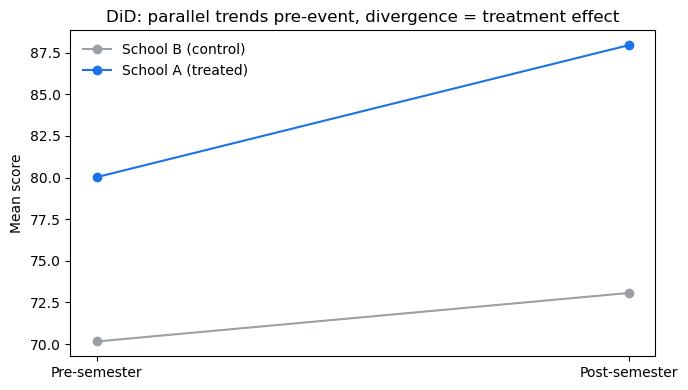

In [3]:
# Q2: DiD scenario — free after-school tutoring offered in School A, not in School B
# Truth: tutoring adds tau=5 points. School A starts 10 points ahead (baseline gap)
# and BOTH schools gain 3 points over the semester (common trend). DiD isolates tau
# by subtracting the control school's gain from the treated school's gain.
rng = np.random.default_rng(3)
n, tau = 1000, 5.0
parts = []
for g, gbase in [(0, 0.0), (1, 10.0)]:        # 0 = School B (control), 1 = School A (treated)
    for t, trend in [(0, 0.0), (1, 3.0)]:      # 0 = pre-semester, 1 = post-semester
        score = 70 + gbase + trend + (tau if (g == 1 and t == 1) else 0) + rng.normal(0, 4, n)
        parts.append(pd.DataFrame({'treat': g, 'post': t, 'score': score}))
did = pd.concat(parts, ignore_index=True)
means = did.groupby(['treat', 'post'])['score'].mean()
print(means.round(2).to_string())
print(f"School A gain: {means[(1,1)]-means[(1,0)]:.2f}, School B gain: {means[(0,1)]-means[(0,0)]:.2f}")
print(f"Manual DiD: {(means[(1,1)]-means[(1,0)])-(means[(0,1)]-means[(0,0)]):.3f}  (truth = {tau})")

import statsmodels.formula.api as smf
m = smf.ols('score ~ treat * post', data=did).fit()
print(f"Regression DiD (treat:post): {m.params['treat:post']:.3f}, p={m.pvalues['treat:post']:.1e}")

fig, ax = plt.subplots(figsize=(7, 4))
for g, lbl, c in [(0, 'School B (control)', '#9aa0a6'), (1, 'School A (treated)', '#1a73e8')]:
    ax.plot([0, 1], [means[(g, 0)], means[(g, 1)]], 'o-', c=c, label=lbl)
ax.set(xticks=[0, 1], xticklabels=['Pre-semester', 'Post-semester'], ylabel='Mean score',
       title='DiD: parallel trends pre-event, divergence = treatment effect')
ax.legend(frameon=False); fig.tight_layout(); plt.show()


### Answer to Question 2 — Tutoring DiD: nonzero effect found

**Story.** Two schools give the same exam before and after a semester. Between exams, School A gets free after-school tutoring; School B does not. School A already scores higher (better funding: +10 baseline gap) and both schools drift up (an easier post exam — the common trend). A raw post comparison (87.95 vs 73.07) would credit tutoring with ~15 points, mixing in the baseline gap; a pre/post comparison within A alone (+7.93) mixes in the common trend. DiD subtracts both: (A gain) − (B gain).

**Result: nonzero.** Cell means: B 70.15 → 73.07 (+2.91), A 80.03 → 87.95 (+7.93). Manual DiD = 7.93 − 2.91 = **5.013**, identical to the regression `treat:post` = **5.013** (p ≈ 4e−83) — with balanced cells the two computations coincide. Truth is 5.0, so the estimator recovers it. H₀ (no interaction) is rejected overwhelmingly: **the tutoring effect is real, ≈ +5 points**, and the plot shows it as the post-semester divergence between two otherwise parallel lines.

**Assumption.** Parallel trends: without tutoring, School A would have gained the same +2.91 as B. It holds by construction here; in real data it must be argued (e.g. with multiple pre-periods showing parallel paths) — if A's trajectory was already diverging, DiD misattributes that divergence to tutoring. Other threats: spillover (B students using A's tutoring) and composition change (different students sitting the two exams).
